# Этап 4. Классификация: сдастся ли квартира за 14 дней

Цель — `rented_14` (1 — сдана за 14 дней). Положительный класс — «сдастся».

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             precision_score, recall_score, f1_score, roc_auc_score)

df = pd.read_csv("../data/astana_rent_class.csv")
print(df.shape)
print(df["rented_14"].value_counts(normalize=True).round(3))

(600, 13)
rented_14
0    0.658
1    0.342
Name: proportion, dtype: float64


## П1. Стратифицированное разбиение и базовые модели

Классы несбалансированы (≈34 % единиц), поэтому `stratify=y`. `id` и `date` в признаки не берём.

In [2]:
num_cols = ["rooms", "area", "floor", "floors", "year", "dist_center", "price", "photos"]
cat_cols = ["district", "furniture"]
X, y = df[num_cols + cat_cols], df["rented_14"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
print(X_train.shape, X_test.shape, y_train.mean().round(3), y_test.mean().round(3))

prep = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
    (make_pipeline(SimpleImputer(strategy="most_frequent"),
                   OneHotEncoder(handle_unknown="ignore")), cat_cols))
model = make_pipeline(prep, LogisticRegression())

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Dummy accuracy:", round(accuracy_score(y_test, dummy.predict(X_test)), 3))
model.fit(X_train, y_train)
print("LogReg accuracy:", round(model.score(X_test, y_test), 3))

(450, 10) (150, 10) 0.342 0.34
Dummy accuracy: 0.66
LogReg accuracy: 0.72


Константа получает accuracy 0,66, не найдя ни одной быстрой сделки. Логистическая регрессия даёт 0,72, но accuracy при таком дисбалансе мало говорит о качестве: смотрим матрицу ошибок.

## П2. Матрица ошибок и ручной расчёт метрик

[[84 15]
 [27 24]]


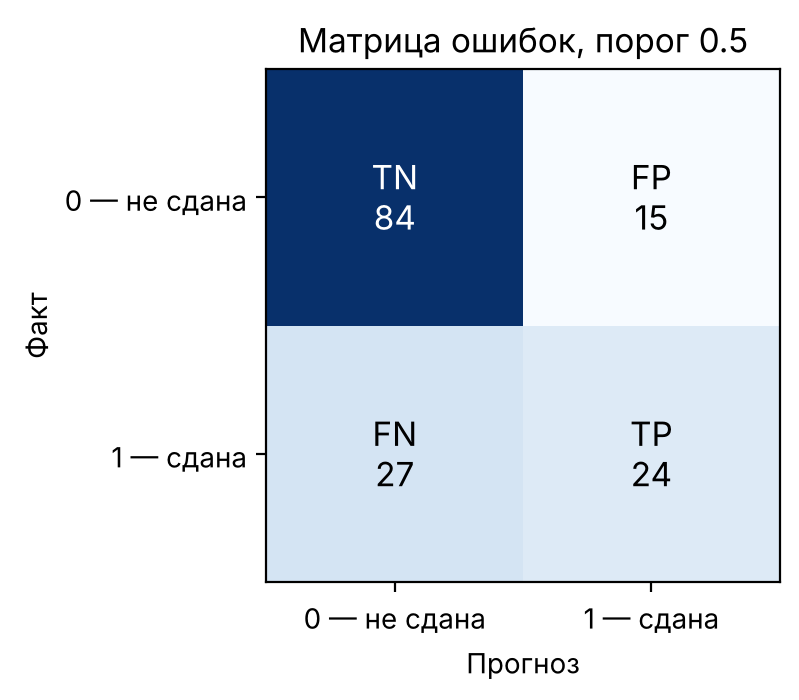

In [3]:
pred = model.predict(X_test)
cm = confusion_matrix(y_test, pred)
tn, fp, fn, tp = cm.ravel()
print(cm)

fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(cm, cmap="Blues")
for (i, j), v, name in zip([(0, 0), (0, 1), (1, 0), (1, 1)], [tn, fp, fn, tp], ["TN", "FP", "FN", "TP"]):
    ax.text(j, i, f"{name}\n{v}", ha="center", va="center",
            color="white" if v > 50 else "black", fontsize=12)
ax.set_xticks([0, 1], ["0 — не сдана", "1 — сдана"])
ax.set_yticks([0, 1], ["0 — не сдана", "1 — сдана"])
ax.set_xlabel("Прогноз"); ax.set_ylabel("Факт")
ax.set_title("Матрица ошибок, порог 0.5")
plt.tight_layout(); plt.savefig("../reports/confusion_matrix.png", dpi=150); plt.show()

In [4]:
# ручной расчёт по матрице
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)
print(f"TN={tn} FP={fp} FN={fn} TP={tp}")
print(f"precision = {tp}/{tp+fp} = {precision:.3f}")
print(f"recall    = {tp}/{tp+fn} = {recall:.3f}")
print(f"F1        = {f1:.3f}")

# сверка с sklearn
print(classification_report(y_test, pred, digits=3))
assert abs(precision - precision_score(y_test, pred)) < 1e-9
assert abs(recall - recall_score(y_test, pred)) < 1e-9
assert abs(f1 - f1_score(y_test, pred)) < 1e-9
print("Ручной расчёт совпал с sklearn")

TN=84 FP=15 FN=27 TP=24
precision = 24/39 = 0.615
recall    = 24/51 = 0.471
F1        = 0.533
              precision    recall  f1-score   support

           0      0.757     0.848     0.800        99
           1      0.615     0.471     0.533        51

    accuracy                          0.720       150
   macro avg      0.686     0.660     0.667       150
weighted avg      0.709     0.720     0.709       150

Ручной расчёт совпал с sklearn


**Словами заказчика.** Из 150 объявлений тестовой выборки 51 действительно сдалось за две недели.

- Подсказка «скорее всего сдастся» верна в 62 % случаев (precision = 24/39). В остальных 15 случаях арендодатель успокоен зря (FP) и не поправит цену или фото.
- Модель распознала только 47 % быстрых сделок (recall = 24/51). По 27 квартирам, которые всё-таки сдались, она сказала «есть риск» (FN): арендодатель мог зря менять цену.
- Accuracy 0,72 выглядит прилично, но скрывает, что больше половины быстрых сделок модель пропускает. При пороге 0,5 она слишком осторожна, порог стоит исследовать (П3).

## П3. Выбор порога на кросс-валидации

Вероятности получаем на обучающей выборке через `cross_val_predict`: каждый объект оценивается моделью, которая его не видела. Тест для выбора порога не используется.

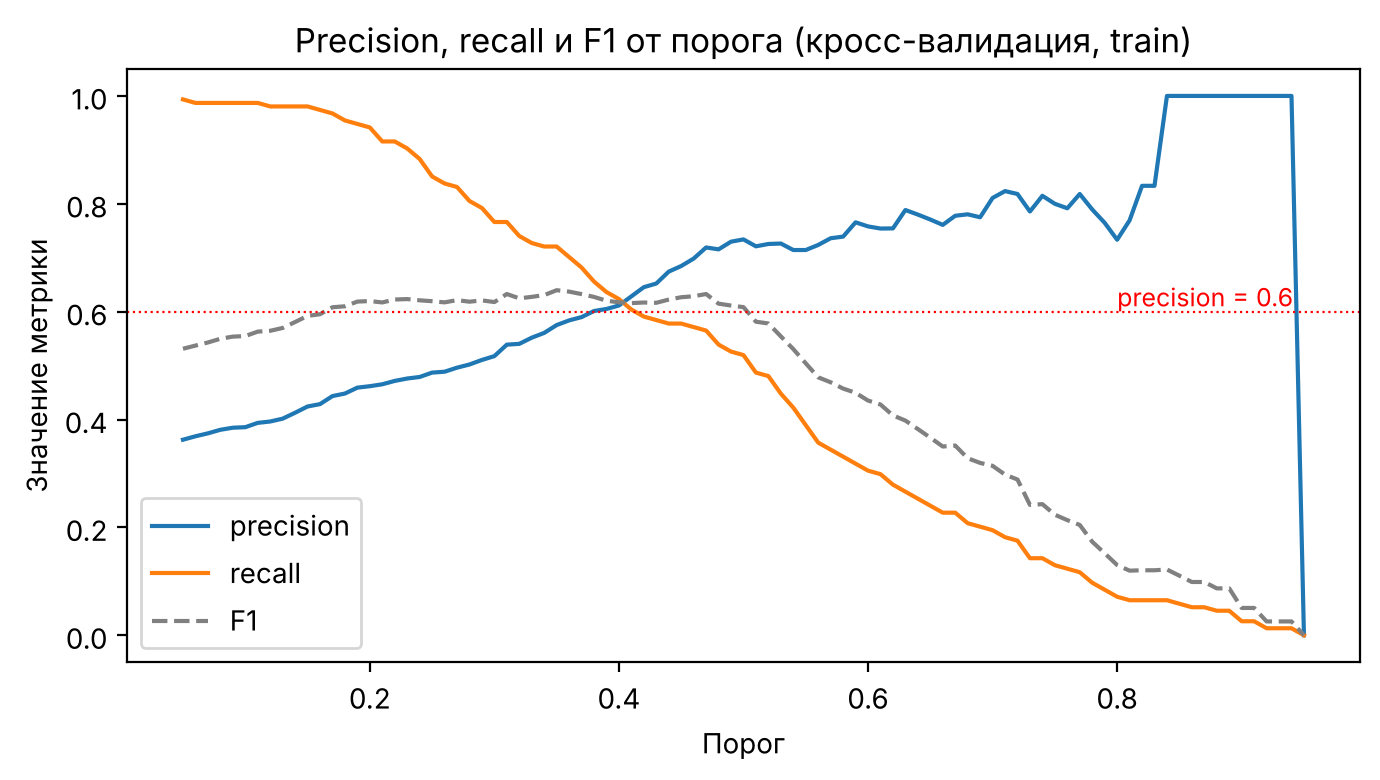

In [5]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof = cross_val_predict(model, X_train, y_train, cv=skf, method="predict_proba")[:, 1]

ths = np.arange(0.05, 0.96, 0.01)
P = np.array([precision_score(y_train, oof >= t, zero_division=0) for t in ths])
R = np.array([recall_score(y_train, oof >= t) for t in ths])
F = np.array([f1_score(y_train, oof >= t) for t in ths])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ths, P, label="precision"); ax.plot(ths, R, label="recall"); ax.plot(ths, F, "--", color="gray", label="F1")
ax.axhline(0.6, color="red", lw=0.8, ls=":")
ax.text(0.8, 0.61, "precision = 0.6", color="red", fontsize=9)
ax.set_xlabel("Порог"); ax.set_ylabel("Значение метрики")
ax.set_title("Precision, recall и F1 от порога (кросс-валидация, train)")
ax.legend(); plt.tight_layout(); plt.savefig("../reports/threshold_curve.png", dpi=150); plt.show()

In [6]:
# таблица по шагу 0.05: на мелком шаге максимум F1 — это подгонка под шум
for t in np.arange(0.3, 0.61, 0.05):
    p = oof >= t
    print(f"t={t:.2f}  precision={precision_score(y_train, p):.3f}  "
          f"recall={recall_score(y_train, p):.3f}  f1={f1_score(y_train, p):.3f}")

# правило: ложное «сдастся» (FP) дороже, поэтому требуем precision >= 0.6,
# а среди таких порогов берём с наибольшим F1
grid = np.arange(0.30, 0.61, 0.05)
ok = [t for t in grid if precision_score(y_train, oof >= t) >= 0.6]
best = max(ok, key=lambda t: f1_score(y_train, oof >= t))
print("выбранный порог:", round(best, 2))

t=0.30  precision=0.518  recall=0.766  f1=0.618
t=0.35  precision=0.575  recall=0.721  f1=0.640
t=0.40  precision=0.611  recall=0.623  f1=0.617
t=0.45  precision=0.685  recall=0.578  f1=0.627
t=0.50  precision=0.734  recall=0.519  f1=0.608
t=0.55  precision=0.714  recall=0.390  f1=0.504
t=0.60  precision=0.758  recall=0.305  f1=0.435
выбранный порог: 0.45


**Выбор порога.** Ложная подсказка «сдастся» (FP) для заказчика дороже пропуска: арендодатель оставляет цену, и квартира простаивает. Поэтому из порогов, где precision на кросс-валидации не ниже 0,6, берём тот, где F1 максимален. Порог 0,5 даёт recall около 0,52, порог ниже 0,4 роняет precision до 0,5–0,6. Выбранное значение записывается в `params_clf.json` в ветке `exp/threshold`.

In [7]:
# контроль: один раз смотрим на тест при выбранном пороге и при 0.5
for t in [0.5, best]:
    p = (model.predict_proba(X_test)[:, 1] >= t).astype(int)
    print(f"t={t:.2f}  precision={precision_score(y_test, p):.3f}  "
          f"recall={recall_score(y_test, p):.3f}  f1={f1_score(y_test, p):.3f}")

t=0.50  precision=0.615  recall=0.471  f1=0.533
t=0.45  precision=0.587  recall=0.529  f1=0.557
